#### Setup

In [1]:
import os, shutil, subprocess, sys
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat.ledger import Ledger, Ref

scratch_path = Path("scratch/q-values").resolve()
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in ("geometry", "plane", "plane.measure", "clips"):
    sys.modules.pop(module_name, None)
sys.path.insert(0, str(Path("demo_game").resolve()))   # the Video class

os.environ["DAT_KEPT"] = str(scratch_path / "kept")   # where v.seal() records local seals
L = Ledger(scratch_path / "ledger", create=True)

# Quick: values

A value is a Python object stored in the ledger by its content: its
hash is its subject, and once stored it never changes. The quick
tour: store and name a value, find it by its preds, compute values
with ledger functions, and let the ledger remember their results.

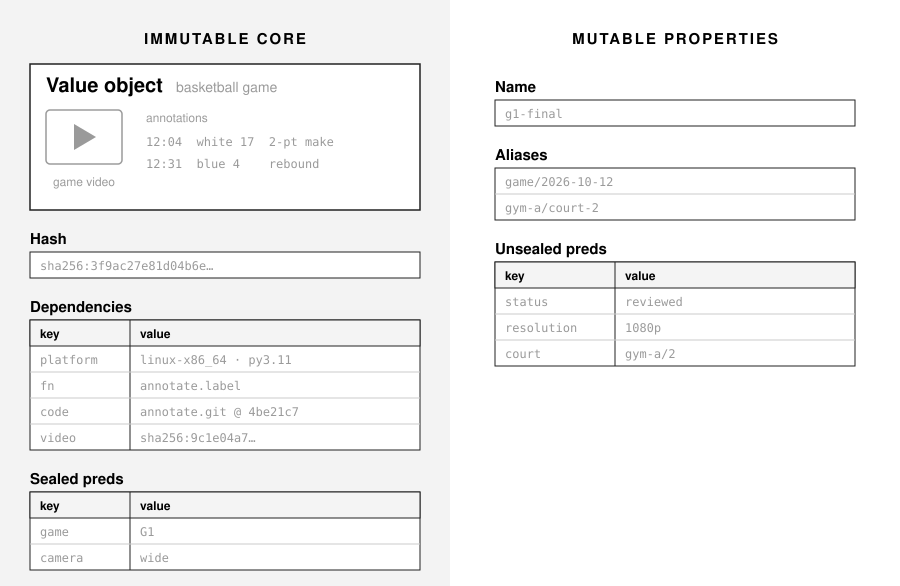

In [2]:
display(SVG(filename="q-values.svg"))   # black: the parts every value has; gray: an example

## Value objects

A value's class is a `Value` subclass in a module (here
`demo_game/game.py`), saying how the object becomes bytes and back,
and which preds (searchable string rows) it carries:

```python
@ledger_class(preds=("game", "camera", "span"))
class Video(Value):
    def __init__(self, frames: bytes):
        self.frames = frames
    def encode(self) -> bytes:
        return self.frames
    @classmethod
    def decode(cls, data: bytes, store) -> "Video":
        return cls(data)
```

### Storing a value, with its name

In [3]:
from demo_game.game import Video

video_value = Video(b"G1 wide camera, 9000 frames")
video_value.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan") as t:
    video_subject = video_value.seal(t, name="video/G1")
print(video_value)          # → video/G1
print(len(video_subject))   # → 64: a hash of the content

video/G1
64


`seal` stores the value and names it in one step. After the seal
the value, its preds included, is frozen.

### Referring to it: by name or by hash

In [4]:
rev1 = L.at()
by_name_video = rev1.load("video/G1")
by_hash_video = rev1.load(video_subject)
print(by_name_video.frames)                        # → b'G1 wide camera, 9000 frames'
print(by_name_video.subject == by_hash_video.subject)   # → True

b'G1 wide camera, 9000 frames'
True


### Assigning preds, and finding values by them

Preds set before the seal are written with it, as rows on the
value's subject.

In [5]:
g2_video = Video(b"G2 wide camera, 8400 frames")
g2_video.preds.update(game="G2", camera="wide")
with L.transaction(by="human:dan") as t:
    g2_subject = g2_video.seal(t, name="video/G2")
rev2 = L.at()
print(rev2.values(camera="wide"))           # → [video/G1, video/G2]
print(rev2.value(game="G1", camera="wide")) # → video/G1
print(rev2.refs(kind=Video))                # → [video/G1, video/G2]

[video/G1, video/G2]
video/G1
[video/G1, video/G2]


`values` loads every match, `value` exactly one, `refs` the
matches unloaded.

#### Updating a pred

The preds the class declares (`game`, `camera`, `span`) are sealed
with the value and never change. Any other pred is a row written
beside it: assigned in one transaction, updated in the next, and
the finders follow it.

In [6]:
with L.transaction(by="human:dan") as t:
    t[g2_subject, "status"] = "raw"
rev3 = L.at()
with L.transaction(by="human:dan", why="G2 reviewed") as t:
    t[g2_subject, "status"] = "reviewed"
print(rev3.values(status="raw"))        # → [video/G2]
print(L.at().values(status="raw"))      # → []
print(L.at().values(status="reviewed")) # → [video/G2]

[video/G2]
[]
[video/G2]


### Values are immutable; their names, aliases and preds are not

The bytes behind a hash, and the preds sealed with them, never
change. A name, an alias or any other pred is a row beside the
value, and rows can be written any time.

#### Adding an alias

An alias is a `db/alias` row pointing at the value's subject. Any
number may point at one value; its name is the alias written
latest.

In [7]:
with L.transaction(by="human:dan") as t:
    t.add("raw/G1/wide-camera", "db/alias", video_subject)
camera_ref = Ref(L.at(), "video/G1")
print(sorted(camera_ref.aliases))   # → ['raw/G1/wide-camera', 'video/G1']
print(camera_ref.name)              # → raw/G1/wide-camera

['raw/G1/wide-camera', 'video/G1']
raw/G1/wide-camera


A `Ref` points at a value without fetching its bytes.

#### Renaming: a new alias, the old one removed

In [8]:
with L.transaction(by="human:dan") as t:
    t.add("game/G2/baseline", "db/alias", g2_subject)
    t.remove("video/G2", "db/alias", g2_subject)
g2_ref = Ref(L.at(), g2_subject)
print(g2_ref.aliases, g2_ref.name)   # → ['game/G2/baseline'] game/G2/baseline

['game/G2/baseline'] game/G2/baseline


#### Adding and changing a pred

A pred the class never declared can be added too.

In [9]:
with L.transaction(by="human:dan", why="format survey") as t:
    for video_ref in L.at().refs(kind=Video):
        t.add(video_ref.subject, "resolution", "1080p")
with L.transaction(by="human:dan", why="G2 was re-encoded") as t:
    t[g2_subject, "resolution"] = "720p"
print(Ref(L.at(), video_subject).preds["resolution"])   # → 1080p
print(Ref(L.at(), g2_subject).preds["resolution"])      # → 720p

1080p
720p


## Ledger functions

A ledger function is a Python function the ledger knows by dotted
name; it takes the revision first, and its result is sealed as a
value. It lives in a git repository, so the ledger can record
exactly which code ran.

### Set up repo and code

One git repository, `geometry`, holds both functions used below:
`geometry.distance` runs in this process; `plane.measure.length`
runs sandboxed.

In [10]:
# setup: create the repo in a folder, with these two source files, and commit them
repo_path = scratch_path / "geometry"
(repo_path / "plane").mkdir(parents=True)
(repo_path / "geometry.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

@ledger_fn
def distance(rev, a, b=(0, 0)) -> float:
    return math.dist(a, b)
''')

(repo_path / "plane/measure.py").write_text('''\
import math
from dvc_dat.ledger import ledger_fn

@ledger_fn
def length(rev, a, b) -> float:
    return math.dist(a, b) * 0.5     # metres per unit
''')

git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]
subprocess.run(git_cmd + ["init", "-q"], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["add", "."], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "geometry and plane"], cwd=repo_path, check=True)

sys.path.insert(0, str(repo_path))

### Accessing and using Python functions

In [11]:
distance_fn = L.at().load_fn("geometry.distance")
hypotenuse_value = distance_fn(a=(3, 4))
print(hypotenuse_value.obj, hypotenuse_value.sealed)
# → 5.0 <the seal's moment>

5.0 2026-10-24T18:59:08Z


`load_fn` finds the function; calling it runs it and seals the
plain `float` it returns as a value (`.obj` unboxes it).

### Sandboxed functions

A sandboxed function runs isolated, seeing only its mounted source
folder, so its version is a checksum of the files it loaded rather
than a git commit. A mount is two rows: the folder, and the repo
that holds it.

In [12]:
with L.transaction(by="human:dan") as t:
    t.add("db/mount/plane", "db/root", "plane")
    t.add("db/mount/plane", "db/repo", "geometry")

length_fn = L.at().load_fn("plane.measure.length")
segment_value = length_fn(a=(0, 0), b=(3, 4))
print(length_fn.mode, segment_value.obj)   # → sandbox 2.5

sandbox 2.5


#### A sandbox is one version of its code

Loading a sandboxed function pins the code it runs: `sha` is the
checksum of the file it loaded, and `subject` names the function
at that version. Every result records it among its dependencies.

In [13]:
print(length_fn.sha[:12])    # → c0edae70e5dc: the checksum of plane/measure.py
print(length_fn.subject)     # → db/fn/plane.measure.length/054ba34c4c9343da
print(segment_value.dependencies)
# → {'fn': 'db/fn/plane.measure.length/054ba34c4c9343da', 'platform': <this machine>}

0fc940ed13c9
db/fn/plane.measure.length/bab093250d0dffef
{'fn': 'db/fn/plane.measure.length/bab093250d0dffef', 'platform': 'darwin-arm64-py3.11'}


Change the code and the function is a new one, with a new
identity. The old result still names the version that made it.

In [14]:
measure_path = repo_path / "plane/measure.py"
measure_path.write_text(measure_path.read_text().replace("* 0.5 ", "* 0.25"))
subprocess.run(git_cmd + ["commit", "-q", "-am", "quarter metres"], cwd=repo_path, check=True)
new_length_fn = L.at().load_fn("plane.measure.length")
print(new_length_fn.sha[:12], new_length_fn.subject)
# → 70809ccdce2e db/fn/plane.measure.length/637deba82ac19922
print(new_length_fn(a=(0, 0), b=(3, 4)).obj)    # → 1.25
print(segment_value.dependencies["fn"], segment_value.obj)
# → db/fn/plane.measure.length/054ba34c4c9343da 2.5

286c47147df4 db/fn/plane.measure.length/f000d89a5e3f336f


1.25
db/fn/plane.measure.length/bab093250d0dffef 2.5


## Ledger evaluation

`rev.run(name, **keys)` is a lookup and a call, traced: the result
records what it depended on, and is remembered, so asking again is
answered from the ledger.

In [ ]:
far_value = L.at().run("geometry.distance", a=(6, 8))
print(far_value.obj)                       # → 10.0
print(sorted(far_value.dependencies))      # → ['code/geometry', 'fn', 'platform']
top_id = L.at().id

again_value = L.at().run("geometry.distance", a=(6, 8))
print(again_value.subject == far_value.subject,
      L.at().id == top_id)                 # → True True: a hit, nothing written

10.0
['code/geometry', 'fn', 'platform']


True True


The dependencies are the code's commit, the function, and the
platform.

### A new version, and a stale result

A function that loads the video a name points at records that
binding. Seal a new version under the same name and the name
moves; the old result no longer holds, so `run` recomputes.

In [ ]:
(repo_path / "clips.py").write_text('''\
from dvc_dat.ledger import ledger_fn
from demo_game.game import Video

@ledger_fn
def clip(rev, *, video: str, start: int, end: int) -> Video:
    return Video(rev.load(video).frames[start:end])
''')

subprocess.run(git_cmd + ["add", "."], cwd=repo_path, check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "clips"], cwd=repo_path, check=True)

# Computing a Value on the Ledger
opening_clip = L.at().run("clips.clip", video="video/G1", start=0, end=8)
print(opening_clip.frames)                 # → b'G1 wide '

retake_video = Video(b"G1 retake, 9100 frames")
retake_video.preds.update(game="G1", camera="wide")
with L.transaction(by="human:dan", why="the retake") as t:
    retake_video.seal(t, name="video/G1")   # the name moves
rev4 = L.at()
print(opening_clip.matches(rev4))          # → False: video/G1 moved
retake_clip = rev4.run("clips.clip", video="video/G1", start=0, end=8)
print(retake_clip.frames)                  # → b'G1 retak'
print(rev4.load(video_subject).frames)     # → b'G1 wide camera, 9000 frames'

b'G1 wide '


False


b'G1 retak'
b'G1 wide camera, 9000 frames'


A value never changes; a name moves. The old video and the old
clip stay, found by their hashes.

## Provenance

A value a ledger function returns records what it depended on: the
function at its version, the code's commit, the platform, and every
name and value it read. That record is its provenance.

### What a result depends on

In [ ]:
for dep_key, dep_value in sorted(retake_clip.dependencies.items()):
    print(f"{dep_key[:28]:30}= {dep_value[:56]}")

code/geometry                 2aadb1ee
fn                            db/fn/clips.clip/23b49920800da19f
platform                      darwin-arm64-py3.11
ref:demo_game.game.Video:d01  ref:demo_game.game.Video:d010f249b04e397f3178803c474e458
video/G1 db/alias             ref:demo_game.game.Video:d010f249b04e397f3178803c474e458


- `code/geometry`: the commit of the repo the function ran from.
- `fn`: the function at its version, as for the sandbox above.
- `platform`: the machine it ran on.
- `ref:…`: the video bytes it loaded.
- `video/G1 db/alias`: the value the name `video/G1` pointed at.

That last row is how `matches` knew the opening clip was stale: it
names the first video, and the name has since moved to the retake.

In [18]:
first_hash = rev4.load(video_subject).hash
print(opening_clip.dependencies["video/G1 db/alias"].endswith(first_hash))         # → True: the first video
print(retake_clip.dependencies["video/G1 db/alias"].endswith(retake_video.hash))   # → True: the retake

True
True


### Sealing, step by step

Sealing fixes a value: its bytes' hash and its preds, so it can be
checked but not changed. Saving puts the sealed value on the
ledger's timeline. `v.seal(t)` does both at once; here they are
apart.

In [19]:
highlight_video = Video(b"G1 highlights, 600 frames")      # 1. make a value
highlight_video.preds.update(game="G1", camera="wide")

print(highlight_video.seal()[:12])        # 2. seal it, on this machine only → 75b825dc06c0
print(highlight_video.sealed)             # → <the seal's moment>
try:
    highlight_video.preds["camera"] = "baseline"
except Exception as error:
    print(type(error).__name__, error)    # → TypeError cannot modify a sealed value's preds
print(L.at().values(game="G1"))           # → [raw/G1/wide-camera, video/G1]: not on the timeline yet

with L.transaction(by="human:dan", why="keep the highlights") as t:   # 3. keep it
    highlight_video.seal(t, name="video/G1/highlights")
print(L.at().values(game="G1"))           # → [raw/G1/wide-camera, video/G1, video/G1/highlights]

75b825dc06c0
2026-10-24T18:59:10Z
TypeError cannot modify a sealed value's preds
[raw/G1/wide-camera, video/G1]
[raw/G1/wide-camera, video/G1, video/G1/highlights]


A ledger function does all three in one call: it runs, seals the
result with its provenance, and saves it. `memo=False` only runs
it, saving nothing, so the result can be looked at first.

In [20]:
clip_fn = L.at().load_fn("clips.clip")                                # get the function
draft_clip = clip_fn(video="video/G1", start=8, end=16, memo=False)   # run it
print(draft_clip.frames, draft_clip.sealed)   # → b'e, 9100 ' None: not sealed, not saved

kept_clip = clip_fn(video="video/G1", start=8, end=16)                # keep it
print(kept_clip.frames, kept_clip.sealed is not None, kept_clip.subject[:12])
# → b'e, 9100 ' True <its subject>: sealed and on the timeline

b'e, 9100 ' None
b'e, 9100 ' True 534d35c09b79
